In [55]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

In [7]:
def brownian_motion(num_processes, num_points, time):
    """
    This function simulates several independent Brownian Motion processes
    over a given time length sampled over a given number of points 

    Args:
        num_processes (int): number of independent Brownian motion processes to be simulated
        num_points (int): number of points to sample the processes over
        time (float): total length of time to simulate the Brownian motions over

    Returns:
        (arr of floats of size num_points x num_processes): points for each Brownian Motion process at each specified points
        (arr of floats of size num_points): time steps for each point the processes are evaluated at
    """

    B = np.zeros((num_points, num_processes))
    dt = time / (num_points - 1)
    time_steps = np.linspace(0, time, num_points)

    for i in range(num_points - 1):
        rand_increment = np.random.normal(0, dt, num_processes)
        B[i+1] = B[i] + rand_increment

    return B, time_steps

def ito_process(drift, diffusion):
    """
    This function returns the Ito process with a given drift and diffusion component as a function, which may
    later be evaluated for a given simulation of Brownian motion.

    Args:
        drift (function): deterministic term of Ito process that depends on time and the current value
        diffusion (function): non-deterministic term of Ito process that depends on time and the current value

    Returns:
        (function): function that evaluates the associated Ito integral for using Euler's method
    """

    def ito_integral(num_processes, num_points, time):
        B, time_steps = brownian_motion(num_processes, num_points, time)

        for i in range(len(time_steps) - 1):
            break
            
        return 0
    
    return ito_integral

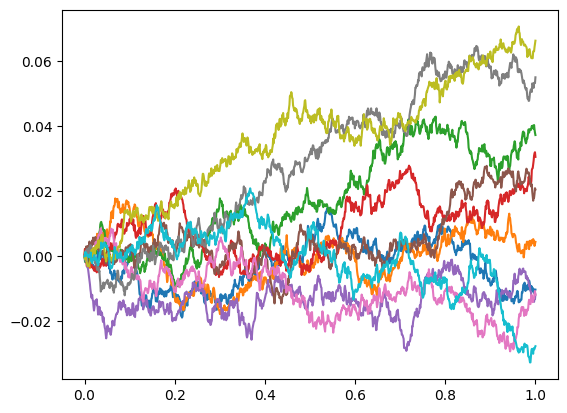

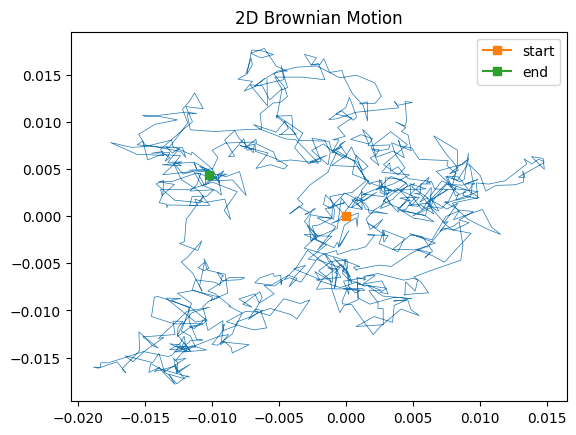

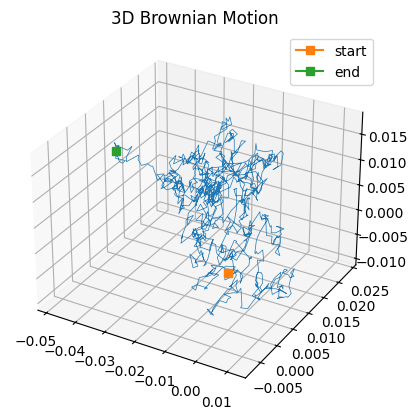

In [23]:
B, t = brownian_motion(10, 1000, 1)
for i in range(10):
    plt.plot(t, B[:, i])
plt.show()

B2, t2 = brownian_motion(2, 1000, 1)
plt.plot(B[:, 0], B[:, 1], linewidth=0.5)
plt.plot(B[0, 0], B[0, 1], marker='s', label='start')
plt.plot(B[-1, 0], B[-1, 1], marker='s', label='end')
plt.title('2D Brownian Motion')
plt.legend()
plt.show()

B3, t3 = brownian_motion(3, 1000, 1)
plt.figure()
ax = plt.axes(projection='3d')
ax.plot3D(B3[:, 0], B3[:, 1], B3[:, 2], linewidth=0.5)
ax.plot3D(B3[0, 0], B3[0, 1], B3[0, 2], marker='s', label='start')
ax.plot3D(B3[-1, 0], B3[-1, 1], B3[-1, 2], marker='s', label='end')
plt.title('3D Brownian Motion')
plt.legend()
plt.show()

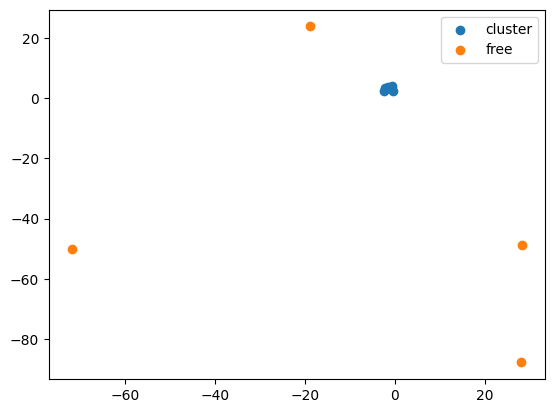

In [314]:
def diffusion_limited_aggregation(num_particles, radius, width, height):
    """
    Simulates 2D Diffusion Limited Aggregation for a given number and size of particles as 
    well as the size of the box containing them

    Args:
        num_particles (int): number of particles starting in the box
        radius (float): size of each particle generated
        width (float): width of the containing box
        height (float): height of the containing box

    Returns:
        ()
    """

    particles = np.stack((np.random.uniform(-width/2, width/2, num_particles),
                         np.random.uniform(-height/2, height/2, num_particles)),
                         axis=1)
    
    # Keep track of particles that are in the cluster: 
    #   1 if they are in the cluster
    #   0 if they are free
    cluster = np.zeros(num_particles)
    cluster[0] = 1

    # while(np.sum(cluster) < 1000):
    for i in range(10000):
        dla_step(particles, cluster, radius, width, height)

    return particles, cluster

def dla_step(particles, cluster, radius, width, height):
    """
    Simulates one step of a 2D Diffusion Limited Aggression process. Moves each free particle, 
    checks if they are within the boundary conditions, and adds them to the cluster if the radius
    of a cluster and free particle overlaps.

    Args:
        particles (2D array of floats): positions of every particle in the process
        cluster (1D array of ints): value determining if each particle is in the cluster
        radius (float): size of radius of each given particle
        width (float): width of the boundary containing box
        height (float): height of the boundary containing box

    Returns:

    """
    free = (cluster == 0)

    # Move each free particle
    particles[free] += np.random.uniform(-1, 1, (len(particles[free]), 2))

    # Check particles around boundary condition
    np.clip(particles[free][:, 0], -width/2, width/2)
    np.clip(particles[free][:, 1], -height/2, height/2)

    # Check if free particles are close enough to cluster particles
    cluster = check_cluster(particles, cluster, radius)

    return particles, cluster

def check_cluster(particles, cluster, radius):
    """
    Checks which free particles intersect with cluster particles and adds them to the cluster.

    Args:
        particles (2D array of floats): positions of every particle in the process
        cluster (1D array of ints): value determining if each particle is in the cluster
        radius (float): size of radius of each given particle

    Returns:
        (1D array of ints): updated array of cluster particles
    """
    cluster_particles = particles[cluster == 1]
    free_particles = particles[cluster == 0]

    # Compute array of distances between cluster and free particles
    dist = cdist(cluster_particles, free_particles)

    # Update cluster array if distance between any pair of 
    # cluster and free particles is less than 2 * radius
    free_index = np.where(cluster == 0)[0]
    intersect = (dist < 2 * radius).any(axis = 0)
    cluster[free_index[intersect]] = 1

    return cluster

particles, cluster = diffusion_limited_aggregation(10, 0.5, 10, 10)
free = particles[cluster == 0]
cluster = particles[cluster > 0]
plt.scatter(cluster[:, 0], cluster[:, 1], label='cluster')
plt.scatter(free[:, 0], free[:, 1], label='free')
plt.legend()
plt.show()